# **Algunas visualizaciones de attention**

En este notebook exploraremos algunas visualizaciones del modelo de attention a través de [BERT](https://huggingface.co/docs/transformers/model_doc/bert).

BERT es un modelo transformer **encoder-only** ,esto significa que solo usa la mitad "de entender" de la arquitectura completa (sin decoder, sin
generación de texto palabra por palabra).

Fue entrenado por Google, ya con sus pesos ajustados
(pre-entrenado) sobre grandes cantidades de texto

No lo vamos a entrenar nosotros, solo vamos a usar un
modelo que ya aprendió a calcular attention de forma útil.

`bert-base-uncased`:
- **base** = el tamaño más chico de BERT (12 capas,
  12 cabezas por capa)
- **uncased** = no distingue mayúsculas de minúsculas
  ("The" y "the" se tratan igual)

La primera vez que corran esta celda, va a descargar
el modelo desde [HuggingFace](https://huggingface.co/) (una plataforma que aloja modelos pre-entrenados), por lo que puede tardar un poco, es normal.

In [13]:
import numpy as np
import matplotlib.pyplot as plt

In [14]:
!pip install bertviz -q #se corre solo una vez!


In [15]:
#se corre solo una vez para cargar el modelo
from bertviz import head_view
from transformers import BertTokenizer, BertModel

model = BertModel.from_pretrained('bert-base-uncased', output_attentions=True)
tokenizer = BertTokenizer.from_pretrained('bert-base-uncased')

print("Modelo cargado, listo para usar")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Modelo cargado, listo para usar


# 1. Multi-head attention

El transformer no hace attention una sola vez, la repite en varias capas apiladas

- Layer = en cuál de esas capas estás mirando
(BERT-base tiene 12 capas, apiladas una sobre otra)

- Head = dentro de esa capa, cuál cabeza de multi-head
attention estás mirando
(BERT-base tiene 12 cabezas, en paralelo, dentro de cada capa)

12 capas × 12 cabezas = 144 "vistas" de attention distintas
en todo el modelo

La cabeza roja en la Layer 3 no tiene relación directa
con la cabeza roja en la Layer 8, son patrones independientes

In [16]:
#frase = "The trophy didn't fit in the suitcase because it was too big"
#frase = "The city council refused the demonstrators a permit because they feared violence"
#frase = "The animal didn't cross the street because it was too tired"
frase = "Vicente doesn't love his brother because he is bad"

inputs = tokenizer.encode(frase, return_tensors='pt')
outputs = model(inputs)
attention = outputs.attentions
tokens = tokenizer.convert_ids_to_tokens(inputs[0])

head_view(attention, tokens)

<IPython.core.display.Javascript object>

### **Actividad**

1. Escribe tu propia oración con una palabra ambigua
   (que podría referirse a más de una cosa). Reemplaza
   el texto en "oracion" en la celda de arriba

2. Antes de correr, predice a mano a qué palabra debería
   atender esa palabra ambigua

3. Corre la celda. Haz clic en la palabra ambigua en el
   visualizador para ver las líneas de atención

4. Compara: ¿acertaste? ¿Qué cabeza (color) capturó la
   relación que esperabas?

La prediccion esperada es que el modelo relacione "he" pueder relacionarse con "Vicente" y "brother". Probablemente el modelo le asigne el "he" a brother. Es la interpretación mas natural.

En la cabeza roja conecta 'he' principalmente con 'brother', lo que coincide con mi predicción. Sin embargo, también atiende fuerte a 'because', así que podría deberse a la cercanía y no a entender la referencia. La cabeza naranja muestra algo de atención hacia 'vicente', pero más débil.

# 2. Self-attention con pesos reales

Ahora usamos las matrices W_Q, W_K, W_V que BERT realmente
aprendió durante su entrenamiego — el mismo cálculo que ya
programaron a mano, pero con pesos entrenados en vez de
aleatorios.

Prueben cambiar `num_capa` (0 a 11) y comparen los patrones:

- Capas tempranas (0-1): attention más local, o colapsando
  hacia tokens especiales como [CLS]
- Capas intermedias/profundas: patrones distintos, pero
  cuidado: este código combina las 12 cabezas en un solo
  promedio, así que relaciones específicas pueden diluirse acá

Si el resultado no muestra una relación "clara" como en
BertViz, no es un error: significa que esa relación vivía
en UNA cabeza específica, no en el promedio de las 12.


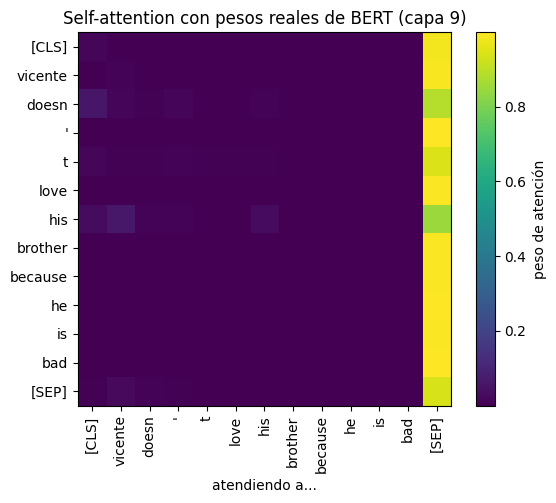

In [17]:
# Elegir qué capa mirar (0 a 11)
num_capa = 9

inputs = tokenizer(frase, return_tensors='pt') #tokenizador de la frasw
outputs = model(**inputs, output_hidden_states=True) #guarda el resultado de cada capa

# hidden_states[0] = embeddings originales (entrada a la capa 0)
# hidden_states[N] = salida de la capa N-1 (entrada a la capa N)
entrada_a_esta_capa = outputs.hidden_states[num_capa].detach().numpy()[0]
tokens = tokenizer.convert_ids_to_tokens(inputs['input_ids'][0])

capa = model.encoder.layer[num_capa].attention.self
#matrices de pesos reales ya entrenados de BERT
W_Q_real = capa.query.weight.detach().numpy()
W_K_real = capa.key.weight.detach().numpy()
W_V_real = capa.value.weight.detach().numpy()

# @ en numpy es el operador de multiplicación de matrices
Q = entrada_a_esta_capa @ W_Q_real.T
K = entrada_a_esta_capa @ W_K_real.T
V = entrada_a_esta_capa @ W_V_real.T

d = Q.shape[1]
#producto punto escalado de attention
scores = (Q @ K.T) / np.sqrt(d)
exp_scores = np.exp(scores - scores.max(axis=1, keepdims=True)) #softmax
pesos_atencion = exp_scores / exp_scores.sum(axis=1, keepdims=True)

#visualización
plt.figure(figsize=(6,5))
plt.imshow(pesos_atencion, cmap="viridis")
plt.xticks(range(len(tokens)), tokens, rotation=90)
plt.yticks(range(len(tokens)), tokens)
plt.xlabel("atendiendo a...")
plt.colorbar(label="peso de atención")
plt.title(f"Self-attention con pesos reales de BERT (capa {num_capa})")
plt.tight_layout()
plt.show()

## Eligiendo un num_capa = 0


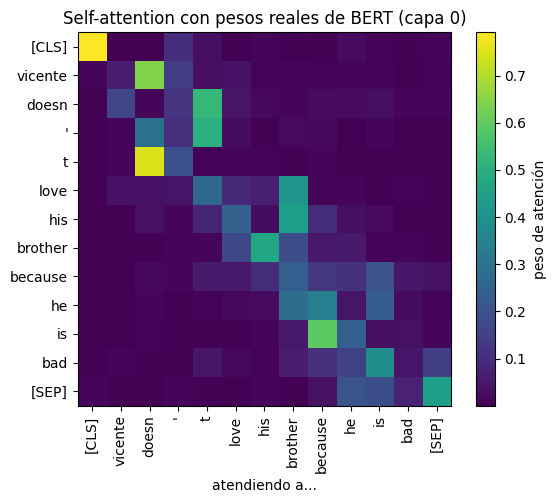

In [18]:
# Elegir qué capa mirar (0 a 11)
num_capa = 0

inputs = tokenizer(frase, return_tensors='pt') #tokenizador de la frasw
outputs = model(**inputs, output_hidden_states=True) #guarda el resultado de cada capa

# hidden_states[0] = embeddings originales (entrada a la capa 0)
# hidden_states[N] = salida de la capa N-1 (entrada a la capa N)
entrada_a_esta_capa = outputs.hidden_states[num_capa].detach().numpy()[0]
tokens = tokenizer.convert_ids_to_tokens(inputs['input_ids'][0])

capa = model.encoder.layer[num_capa].attention.self
#matrices de pesos reales ya entrenados de BERT
W_Q_real = capa.query.weight.detach().numpy()
W_K_real = capa.key.weight.detach().numpy()
W_V_real = capa.value.weight.detach().numpy()

# @ en numpy es el operador de multiplicación de matrices
Q = entrada_a_esta_capa @ W_Q_real.T
K = entrada_a_esta_capa @ W_K_real.T
V = entrada_a_esta_capa @ W_V_real.T

d = Q.shape[1]
#producto punto escalado de attention
scores = (Q @ K.T) / np.sqrt(d)
exp_scores = np.exp(scores - scores.max(axis=1, keepdims=True)) #softmax
pesos_atencion = exp_scores / exp_scores.sum(axis=1, keepdims=True)

#visualización
plt.figure(figsize=(6,5))
plt.imshow(pesos_atencion, cmap="viridis")
plt.xticks(range(len(tokens)), tokens, rotation=90)
plt.yticks(range(len(tokens)), tokens)
plt.xlabel("atendiendo a...")
plt.colorbar(label="peso de atención")
plt.title(f"Self-attention con pesos reales de BERT (capa {num_capa})")
plt.tight_layout()
plt.show()

### **Observe y responda**

- ¿Hacia qué palabra(s) se concentra la mayor parte de la
  atención en esta capa?
- ¿Es un patrón interpretable (relación de significado) o
  parece attention "colapsando" hacia puntuación/tokens
  especiales?
- Compare con el resultado de otra capa: ¿qué cambió?



- En la capa 9, casi toda la atención (aprox. 0.8 a 0.9) va hacia [SEP], desde todos los tokens. En la capa 0, la atención se reparte entre palabras vecinas.

- La capa 9 muestra colapso hacia un token especial, sin relaciones de significado visibles. La capa 0 es más interpretable pero en un sentido posicional. Los fragmentos de "doesn't" se atienden entre sí, y palabras cercanas como "his"/"brother" se conectan. "he" atiende a "brother" y "because" con pesos similares, lo que confirma lo de la actividad 1 -> es por cercanía.

- Se pasa de una atención local y distribuida (capa 0) a una casi totalmente concentrada en [SEP] (capa 9). No aparece una relación clara entre he y brother porque este código junta las 12 cabezas en un solo cálculo, y las relaciones específicas, que viven en cabezas individuales, se diluyen.

# 3. Clasificador de sentimiento

`pipeline("sentiment-analysis")` descarga un modelo ya
entrenado específicamente para una tarea: decidir si un
texto es POSITIVO o NEGATIVO.

Por dentro sigue siendo un transformer (parecido a BERT), con el mismo mecanismo de attention, pero fue
afinado (fine-tuning) con miles de ejemplos de texto
etiquetados como positivo/negativo, hasta aprender a
distinguir el tono de un texto.

El resultado incluye un "label" (POSITIVE o NEGATIVE) y
un "score" (qué tan seguro está el modelo de esa clasificación).

En este caso, usaremos DistilBERT, que está basado en BERT pero es una versión más comprimida.

- BERT-base: 12 capas, 768 dimensiones, ~110 millones de parámetros

- DistilBERT: 6 capas (la mitad), misma dimensión (768),
                 ~66 millones de parámetros
                 → ~40% más chico, ~60% más rápido,
                 conservando ~97% del rendimiento de BERT
                 en varias tareas

In [24]:
frases = [
    "Vicente loves his brother",
    "Vicente hates his brother",
    "Wow, Vicente is such a great brother, he only hit his brother once",
]

In [25]:
from transformers import pipeline

clasificador = pipeline("sentiment-analysis", model="distilbert-base-uncased-finetuned-sst-2-english") #modelo fine-tuned para análisis de sentimiento

frase="I love how transformers actually make sense now"

resultado = clasificador(frase)
print(resultado)

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

[{'label': 'POSITIVE', 'score': 0.9997923970222473}]


In [26]:
for f in frases:
    print(f, "->", clasificador(f))

Vicente loves his brother -> [{'label': 'POSITIVE', 'score': 0.9983924031257629}]
Vicente hates his brother -> [{'label': 'NEGATIVE', 'score': 0.9981375932693481}]
Wow, Vicente is such a great brother, he only hit his brother once -> [{'label': 'POSITIVE', 'score': 0.9410400390625}]


### **Actividad**

1. Cambie "frase" por algo suyo; pueden probar una
   frase claramente positiva, una negativa, y una ambigua
   o irónica (ej. "great, another Monday")

2. Observe el "score" (la probabilidad), no solo el
   label. ¿Qué tan seguro está el modelo?

3. Pruebe una oración con sarcasmo o doble sentido.
   ¿El modelo lo detecta, o falla?

2. En las frases claras el modelo está casi completamente seguro (score de aprox. 0.998 en ambas) y acierta. En la sarcástica el score baja a 0.94, pero sigue siendo muy alto. Hay que tener en cuenta que el score es la salida de un softmax y no una confianza calibrada por lo que un valor alto no garantiza que la clasificación sea correcta.

3. El modelo no detecta el sarcasmo. Clasifica la frase como POSITIVE, aunque el significado es claramente negativo. Esto sugiere que se apoya mucho en palabras con carga positiva como "great" y "wow", y no logra captar que el contexto ("he only hit his brother once") invierte el sentido. Incluso la presencia de "hit", una palabra negativa, no fue suficiente para cambiar la clasificación.

###

# 4. Extrayendo embeddings de una oración

`pipeline("feature-extraction")` toma un texto y devuelve
un vector numérico para cada token de esa oración, que es la
representación final que BERT genera después de procesar
toda la oración a través de sus 12 capas.

Estos vectores capturan tanto el significado de cada palabra
como el contexto de las palabras que la rodean. Se usan,
por ejemplo, para comparar qué tan similares son dos textos,
o como entrada para otro modelo que necesite trabajar con
texto ya convertido a números.

El resultado es una matriz: una fila por token, y cada fila
tiene 768 números (el tamaño del vector que usa BERT-base).



In [27]:
extractor = pipeline("feature-extraction", model="bert-base-uncased")

embedding = extractor("The animal didn't cross the street because it was too tired")
print("Forma del embedding:", len(embedding[0]), "(filas) x", len(embedding[0][0]), "(columnas)")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Forma del embedding: 15 (filas) x 768 (columnas)


## Qué significa la forma del embedding

**X (filas):** es la cantidad de tokens en que quedó
dividida la oración. No es necesariamente la cantidad de
palabras, BERT tokeniza así:

- Agrega [CLS] al principio y [SEP] al final (2 tokens extra)
- Puede partir una palabra en varios pedazos si no la
  reconoce completa en su vocabulario (ej. "didn't" puede
  quedar dividido en "didn" + "'" + "t")

Por eso el conteo final de tokens casi nunca coincide con
contar palabras separadas por espacios.

**768 (columnas):** es el tamaño del vector de embedding
que BERT-base usa para representar cada token. Es un
número fijo, decidido por quienes diseñaron y entrenaron
este modelo específico, no es un valor universal, otros
modelos usan otros tamaños (BERT-large usa 1024, por
ejemplo).

**Entonces la matriz completa (X x 768)** es: por cada uno
de los 11 tokens de la oración, un vector de 768 números
que lo representa

# 5. Embeddings similares

Este código extrae el vector (embedding) que BERT genera
para la palabra "bank" en dos oraciones distintas:

- "I deposited money at the bank" (banco financiero)
- "We sat by the river bank" (orilla de un río)

`obtener_embedding_palabra` tokeniza la oración, la pasa
por el modelo, encuentra la posición exacta de la palabra
"bank" entre los tokens, y devuelve su vector final.

Después se calcula la similaridad coseno entre ambos
vectores, el resultado es un número entre 0 y 1 que mide qué tan parecidos
son. 1 significa idénticos, 0 significa sin relación.

Si el resultado sale bajo, significa que BERT generó
representaciones distintas para la misma palabra, según
el contexto de cada oración.

In [28]:
def obtener_embedding_palabra(frase, palabra_objetivo):
    inputs = tokenizer(frase, return_tensors='pt')
    outputs = model(**inputs)
    tokens = tokenizer.convert_ids_to_tokens(inputs['input_ids'][0])
    idx = tokens.index(palabra_objetivo)
    return outputs.last_hidden_state[0, idx].detach().numpy()

frase1 = "I deposited money at the bank"
frase2 = "We sat by the river bank"

emb1 = obtener_embedding_palabra(frase1, "bank")
emb2 = obtener_embedding_palabra(frase2, "bank")

# Similaridad coseno: 1 = idénticos, 0 = sin relación
similaridad = np.dot(emb1, emb2) / (np.linalg.norm(emb1) * np.linalg.norm(emb2))
print(f"Similaridad entre 'bank' (financiero) y 'bank' (río): {similaridad:.3f}")

Similaridad entre 'bank' (financiero) y 'bank' (río): 0.726


In [30]:
palabra = "right"
f1 = "When you see the tree, you have to turn right"
f2 = "Im here, at your right"
f3 = "I think you are right this time"

print(tokenizer.tokenize(f1), tokenizer.tokenize(f2), tokenizer.tokenize(f3))

e1 = obtener_embedding_palabra(f1, palabra)
e2 = obtener_embedding_palabra(f2, palabra)
e3 = obtener_embedding_palabra(f3, palabra)

def cos(a, b):
    return np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b))

print("mismo significado:", cos(e1, e2))
print("distinto significado:", cos(e1, e3))

['when', 'you', 'see', 'the', 'tree', ',', 'you', 'have', 'to', 'turn', 'right'] ['im', 'here', ',', 'at', 'your', 'right'] ['i', 'think', 'you', 'are', 'right', 'this', 'time']
mismo significado: 0.60794693
distinto significado: 0.36352676


### **Actividad**

1. Elija una palabra en inglés con dos significados
   distintos (ej. "bat" — animal / objeto deportivo,
   "spring" — estación / resorte, "match" — fósforo / partido)

2. Escriba dos oraciones donde esa palabra tenga cada
   significado

3. Reemplace `frase1`, `frase2` y `palabra_objetivo` en
   el código con las suyas, y corra la celda

4. ¿qué tan alta o baja salió la
   similaridad? Tiene sentido?

5. Pruebe también con la **misma** palabra usada dos veces
   con el **mismo** significado, en oraciones distintas
   (ej. "bank" financiero en dos contextos distintos).
   ¿La similaridad sale más alta que en el caso ambiguo?




La similaridad coseno entre las dos frases con el mismo significado fue de 0.61, y entre significados distintos fue de 0.36.

Si tiene sentido. Aunque la palabra es la misma, BERT genera vectores distintos según el contexto, porque cada palabra se mezcla con la información de las que la rodean. Por eso, con el mismo significado los vectores se parecen más (0.61) que con significados distintos (0.36). Igual la similaridad no llega a 0, así que lo importante es comparar los dos valores entre sí.

# 6. Context size

Este código muestra el límite real de tokens que BERT puede
procesar de una vez (`tokenizer.model_max_length`).

Después genera un texto artificialmente largo (la misma
oración repetida 1000 veces) y cuenta cuántos tokens resultan
al tokenizarlo.

Si esa cantidad supera el límite del modelo, lo va a indicar
explícitamente. Esto muestra de forma concreta algo que ya
vimos en la teoría: el contexto no es ilimitado, y un texto
real puede superarlo fácilmente.

In [31]:
# Ver el context size real del modelo que ya tienen cargado
print("Context size máximo de BERT:", tokenizer.model_max_length)

# Generar un texto artificialmente largo y ver qué pasa
texto_largo = "El gato come pescado. " * 1000  # se repite 1000 veces

tokens = tokenizer.encode(texto_largo)
print("Cantidad de tokens generados:", len(tokens))

if len(tokens) > tokenizer.model_max_length:
    print("¡Este texto EXCEDE el límite de contexto del modelo!")

Context size máximo de BERT: 512
Cantidad de tokens generados: 8002
¡Este texto EXCEDE el límite de contexto del modelo!


# **Para las siguientes actividades, use el LLM de su preferencia (ChatGPT, Claude, Gemini, etc)**

## **Actividad: poniendo a prueba el context size**

1. Al empezar una conversación nueva, dile al modelo un
   dato inventado y específico, por ejemplo:
   "Mi número de la suerte es 4173. Recuérdalo."

2. Pégale un texto largo de relleno (puede ser un capítulo
   de Wikipedia, un paper, cualquier texto de varios miles
   de palabras) y pídele que lo resuma.

3. Sigue conversando sobre OTROS temas durante varios
   mensajes más (5-10 intercambios), sin mencionar el
   número de la suerte.

4. Al final, pregúntale: "¿cuál era mi número de la suerte?"

5. ¿lo recordó? ¿Lo recordó mal? Si la conversación
se hizo muy larga, ¿en qué momento empezó a fallar?


**Nota**: los modelos actuales tienen ventanas de contexto
bastante grandes, así que es posible que el modelo SÍ
recuerde el número incluso con texto de relleno largo.
Si eso pasa, pruebe agregando más texto
de relleno, o una conversación más larga, para ver si en
algún punto empieza a fallar.

El modelo (gemini) si recordo el numero de la suerte (192 512), incluso después de pegarle un texto largo (articulo de wikipedia sobre agujeros negros) y de conversar sobre otros temas durante 9 mensajes.

El modelo no llegó a fallar. Esto se debe a que el modelo no "recuerda" como una persona: en cada mensaje vuelve a leer toda la conversación, y mientras quepa en su ventana de contexto, el número sigue ahí. Los LLMs actuales tienen ventanas de cientos de miles de tokens aprox., mucho más que los 512 de BERT así que una conversación normal no alcanza a llenarla.

## **Actividad: ¿Pensar paso a paso mejora las respuestas de un LLM?**

Los modelos de lenguaje pueden equivocarse incluso en tareas aparentemente sencillas, como contar letras. Sin embargo, generar pasos intermedios y verificar sus resultados puede mejorar la precisión (*Chain-of-Thought*).

**1.** En una conversación nueva con un LLM, escriban:

> ¿Cuántas veces aparece la letra «r» en la palabra «ferrocarrilero»? Responde solamente con el número.

**2.** En otra conversación nueva, utilicen el mismo modelo, pero ahora escriban:

> ¿Cuántas veces aparece la letra «r» en la palabra «ferrocarrilero»? Enumera primero las posiciones de cada «r», verifica el conteo y luego entrega el resultado.

**3.** Repitan el experimento con otras palabras de su elección. Comparen los resultados y comprueben las respuestas correctas.

**Para discutir:**

- ¿Observaron diferencias entre las dos estrategias?
- ¿Por qué generar pasos intermedios podría ayudar a resolver el problema?
- ¿Es lo mismo pedirle a un LLM que razone paso a paso que utilizar un *reasoning model*?
- ¿Una explicación detallada garantiza que la respuesta sea correcta?

**Opcional:** repitan el experimento utilizando un modelo Instant y uno de razonamiento. ¿Encuentran diferencias?

*Nota:* No es necesario que el modelo cometa errores. El objetivo es investigar cómo influye la estrategia de generación en los resultados y qué relación tiene con Chain-of-Thought y test-time compute.

probé con ferrocarrilero, electroencefalografista, anticonstitucionalmente, esternocleidomastoideo y otorrinolaringólogo, usando gemini. En casi todas acertó con ambas estrategias, pero en "esternocleidomastoideo" (contando la "o") respondió 3 cuando le pedí solo el número, y 4 (correcto) cuando le pedí enumerar las posiciones primero.

Sí se observan diferencias. En un caso, la respuesta directa falló y la estrategia paso a paso acertó.

Al generar pasas intermedios, el LLM no ve letras, ve tokens (como vimos con BERT, las palabras se parten en pedazos). Al responder directo tiene que "adivinar" el conteo en un solo paso. Al enumerar las posiciones, escribe las letras una por una, y esas letras quedan en su contexto, así que puede contarlas.

No es lo mismo pedirle que razone paso a paso que usar un reasoning model. Con el prompt solo le pido que escriba pasos. Un reasoning model fue entrenado específicamente para razonar antes de responder.

Una explicación detallada no garantiza que la respuesta sea correcta. El modelo puede escribir pasos que se ven coherentes y aun así equivocarse en uno, o dar una explicación que no refleja realmente cómo llegó al resultado.